# 01 · Introducere în datele audio

**Sursa:** [Unit 1 · What you'll learn](https://huggingface.co/learn/audio-course/en/chapter1/introduction) + [Introduction to audio data](https://huggingface.co/learn/audio-course/en/chapter1/audio_data)
**Kernel:** `speech-vlm` (Mac)

**Cum folosești ghidul:**
- 📖 **Teorie**: ce trebuie să reții, pe scurt.
- ▶️ **Cod din curs**: îl rulezi și te uiți la rezultat.
- 🔍 **Ce să observi**: unde să te uiți în grafic sau în output.
- 🧪 **Exercițiu**: cerința e în comentariile `# TODO`, iar soluția e chiar dedesubt. O rulezi, apoi o modifici ca să vezi ce se schimbă.
- 🎯 **Legătura cu proiectul**.

🎯 **De ce contează:** tot ce vezi aici e drumul audio-ului în proiect: undă → eșantioane la 16 kHz → log-mel spectrogram cu 128 de benzi → encoderul Whisper.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display
from IPython.display import Audio

## 1. De la undă sonoră la numere: sampling

📖 **Teorie**
- Sunetul e o undă **continuă** (variații de presiune a aerului), dar un calculator poate stoca doar un număr **finit** de valori.
- Microfonul transformă unda în semnal electric. Un convertor analog-digital îl **eșantionează**, adică îi măsoară valoarea la intervale fixe.
- **Eșantion** (în engleză: **sample**) = **o singură valoare** măsurată din undă, la un anumit moment. Un fișier audio e doar un șir lung de eșantioane: `array[0]`, `array[1]`, `array[2]`, …

> **De ce eșantionăm? Ce obții?**
> - **Scopul:** calculatorul și modelul lucrează doar cu **numere, în cantitate finită**. Sunetul real e continuu, adică are o infinitate de valori. Eșantionarea îl transformă într-o **listă de numere**, pe care o poți salva (fișier `.wav`), procesa (spectrogramă) și da unui model.
> - **Ce obții:** un vector 1-D. `array[i]` e presiunea aerului (normalizată în [-1, 1]) la momentul `i / sampling_rate`. O secundă de vorbire la 16 kHz e un vector de **16.000 de numere**. Exact asta e `array` din secțiunea 3 și din dataset-uri, și exact asta primește Whisper.
> - **Analogie, filmul:** o cameră face 24 de poze pe secundă dintr-o mișcare continuă, iar ochiul vede mișcare fluidă. Microfonul face **16.000 de „poze” pe secundă** ale presiunii aerului. Dacă pozele sunt prea rare, pierzi detaliile rapide (frecvențele înalte) sau apar artefacte. Roata de mașină care pare că se învârte înapoi într-un film e **aliasing**: pozele sunt prea rare față de cât de repede se învârte roata.

> **De ce 16 kHz și nu mai mult?**
> - Sampling rate-ul decide doar **cea mai înaltă frecvență** pe care o poți captura (sr / 2). **Nu reduce zgomotul** și nu face volumul mai precis; de asta se ocupă **bit depth-ul** (secțiunea 2). Sunt două lucruri diferite:
>   - sampling rate = **cât de des** măsori;
>   - bit depth = **cât de precis** măsori fiecare valoare.
> - Informația utilă din vorbire e **sub 8 kHz**, așa că 16 kHz o prinde toată. Muzica la calitate CD folosește 44,1 kHz ca să prindă tot ce aude urechea, până la ~20 kHz, dar pentru recunoașterea cuvintelor nu e nevoie.
> - Un sampling rate mai mare înseamnă doar **mai multe numere**, deci mai mult calcul și mai multă memorie. 30 s înseamnă 480.000 de valori la 16 kHz și 1.323.000 la 44,1 kHz (~2,8×), fără câștig pentru vorbire.
> - Unul mai mic strică. La 8 kHz (calitate de telefon) se pierd frecvențele dintre 4 și 8 kHz, unde stau consoane ca **s**, **ș**, **f**, iar vocea sună „înfundat”.
> - **În practică, cel mai important:** Whisper a fost antrenat la 16 kHz, deci îi dăm exact 16 kHz.
- **Sampling rate** (Hz) = câte eșantioane pe secundă. Pe CD: 44.100 Hz. La modelele de vorbire: **16.000 Hz**.
- **Limita Nyquist:** frecvența maximă pe care o poți captura e **sampling rate / 2**. Vorbirea are frecvențe sub 8 kHz, deci 16 kHz e suficient.
- **Aliasing** (din engleză: *alias* = „nume fals”): o frecvență **peste limita Nyquist** nu poate fi reprezentată corect. Eșantioanele o „văd” ca pe o **frecvență falsă, mai joasă**: unda de 5 Hz eșantionată la 8 Hz apare ca o undă de **3 Hz** (8 − 5). Odată eșantionat, semnalul nu mai poate fi reparat. De aceea, înainte de downsampling, frecvențele prea înalte se elimină cu un **filtru anti-aliasing**.
- 5 secunde la 16 kHz înseamnă **80.000** de valori.
- Toate exemplele dintr-un dataset trebuie să aibă **același** sampling rate, același cu al modelului pre-antrenat. Altfel faci **resampling**.
- `.wav` e necomprimat, `.flac` e comprimat fără pierderi, `.mp3` e comprimat cu pierderi.

▶️ Cursul nu are cod la partea asta, așa că vizualizăm ideea: o undă aproape continuă și eșantioanele ei.

In [ ]:
f = 5                                   # frecvența undei, în Hz
t_cont = np.linspace(0, 1, 10_000)      # 10.000 de puncte într-o secundă ≈ "continuu"
wave = np.sin(2 * np.pi * f * t_cont)

def show_sampling(sr):
    t = np.arange(0, 1, 1 / sr)         # momentele de eșantionare
    plt.figure(figsize=(12, 2.5))
    plt.plot(t_cont, wave, alpha=0.4, label=f"undă continuă ({f} Hz)")
    y = np.sin(2 * np.pi * f * t)
    plt.stem(t, y, basefmt=" ", label=f"eșantioane la {sr} Hz")
    if sr <= 20:                        # numerotăm eșantioanele, ca să le poți număra
        for i, (ti, yi) in enumerate(zip(t, y)):
            plt.annotate(str(i), (ti, yi), textcoords="offset points", xytext=(4, 6), fontsize=9)
    plt.title(f"sampling rate = {sr} Hz → {len(t)} eșantioane într-o secundă | Nyquist = {sr / 2} Hz")
    plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))   # legenda în afara graficului, ca să nu acopere eșantioane
    plt.show()

show_sampling(50)   # mult peste 2 × 5 Hz
show_sampling(8)    # sub 2 × 5 Hz

🔍 **Ce să observi**
- La 50 Hz, eșantioanele urmăresc unda.
- **Cum numeri eșantioanele:** fiecare bețișor cu punct e **un eșantion**. La 8 Hz sunt **8** într-o secundă, numerotate 0–7 pe grafic. Două dintre ele, la 0 s și la 0,5 s, au valoarea 0, așa că apar doar ca puncte pe axă, fără bețișor. De aceea pare că sunt mai puține.
- La 8 Hz, Nyquist e 4 Hz, mai mic decât 5 Hz. Dacă unești punctele, iese o undă de **3 Hz** (8 − 5), care nu există în realitate: un **alias**. Celula de mai jos o desenează.

In [ ]:
# ▶️ Alias-ul, desenat: la 8 Hz, eșantioanele undei de 5 Hz cad exact pe o undă de 3 Hz (= 8 − 5)
sr = 8
t = np.arange(0, 1, 1 / sr)
plt.figure(figsize=(12, 2.5))
plt.plot(t_cont, wave, alpha=0.3, label="unda reală: 5 Hz")
plt.plot(t_cont, -np.sin(2 * np.pi * 3 * t_cont), "r--", label="alias: 3 Hz (8 − 5)")
plt.stem(t, np.sin(2 * np.pi * f * t), basefmt=" ", label="eșantioane la 8 Hz")
plt.title("Aceleași 8 eșantioane se potrivesc pe ambele unde: din eșantioane nu mai poți ști care era cea reală")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

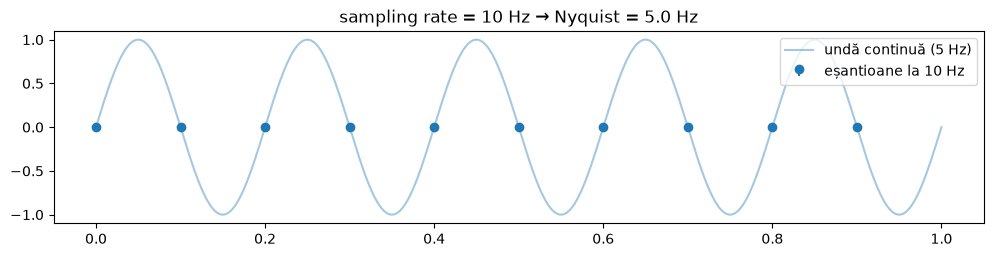

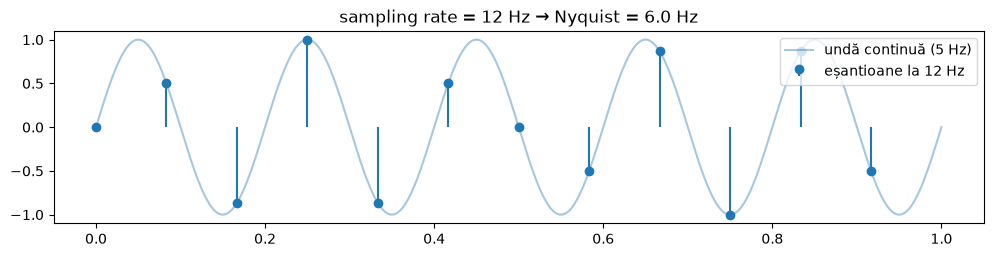

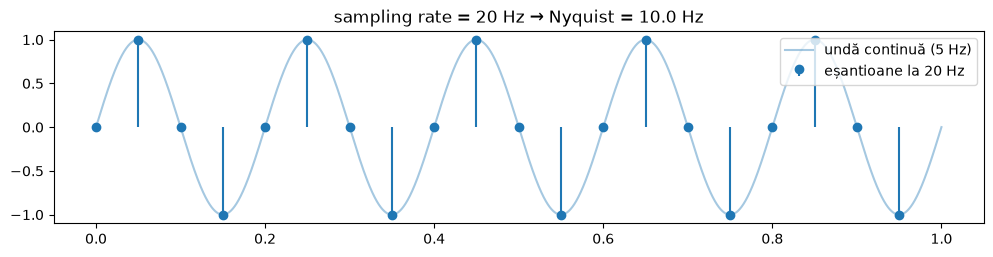

In [3]:
# 🧪 TODO: încearcă show_sampling cu 10, 12 și 20 Hz.
# TODO: de la ce sampling rate în sus urmăresc punctele corect unda de 5 Hz? Leagă răspunsul de Nyquist.
for sr in [10, 12, 20]:
    show_sampling(sr)

# Răspuns: trebuie să fie STRICT peste 10 Hz (= 2 × 5 Hz).
# La exact 10 Hz, toate eșantioanele cad pe zero, iar unda „dispare” complet.

## 2. Amplitudine și bit depth

📖 **Teorie**
- **Amplitudinea** spune cât de tare e sunetul. O percepem ca volum și o măsurăm în decibeli (dB).
- **Bit depth** spune cu câtă precizie salvezi fiecare eșantion: 16 biți = 65.536 de niveluri, 24 de biți = 16.777.216.
- Rotunjirea la cel mai apropiat nivel produce **zgomot de cuantizare**. La 16 biți e deja inaudibil.
- Modelele ML lucrează cu **float32**, cu valori în **[-1.0, 1.0]**.
- În audio digital, **0 dB e sunetul cel mai tare posibil**, iar restul valorilor sunt negative.
- **Regulă practică:** -6 dB înseamnă aproximativ jumătate din amplitudine, iar sub -60 dB sunetul practic nu se mai aude.

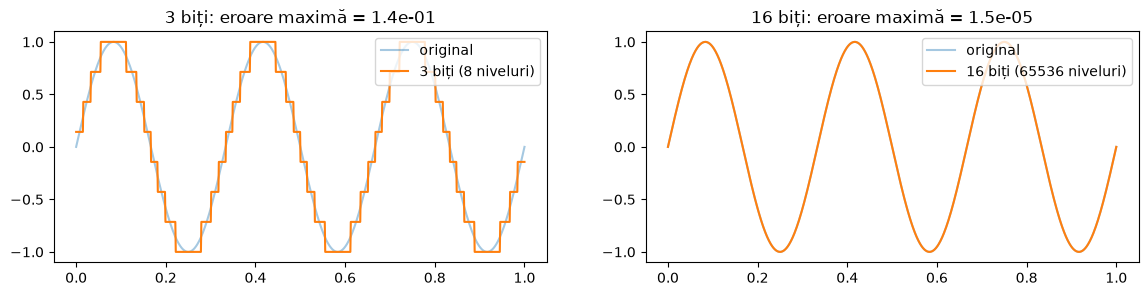

In [4]:
# Aceeași undă, salvată cu 3 biți și cu 16 biți
t = np.linspace(0, 1, 1000)
x = np.sin(2 * np.pi * 3 * t)

def quantize(x, bits):
    levels = 2 ** bits
    return np.round((x + 1) / 2 * (levels - 1)) / (levels - 1) * 2 - 1

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
for a, bits in zip(ax, [3, 16]):
    q = quantize(x, bits)
    a.plot(t, x, alpha=0.4, label="original")
    a.plot(t, q, label=f"{bits} biți ({2 ** bits} niveluri)")
    a.set_title(f"{bits} biți: eroare maximă = {np.abs(q - x).max():.1e}")
    a.legend(loc="upper right")
plt.show()

🔍 **Ce să observi**
- La 3 biți vezi **trepte**. Ele sunt zgomotul de cuantizare.
- La 16 biți eroarea e de ordinul 1e-5, invizibilă.

In [ ]:
# ▶️ Cele două „axe” ale audio-ului digital: sampling rate (orizontal) și bit depth (vertical)
sr_demo, bits_demo = 20, 3
t_c = np.linspace(0, 1, 2000)
t_s = np.arange(0, 1, 1 / sr_demo)
plt.figure(figsize=(12, 3.5))
for v in np.linspace(-1, 1, 2 ** bits_demo):
    plt.axhline(v, color="gray", lw=0.9, alpha=0.8)        # nivelurile permise de bit depth
plt.yticks(np.linspace(-1, 1, 2 ** bits_demo).round(2))   # pe axa y: exact cele 8 niveluri
for ts in t_s:
    plt.axvline(ts, color="orange", lw=0.6, alpha=0.4)     # momentele de eșantionare
plt.plot(t_c, np.sin(2 * np.pi * 2 * t_c), alpha=0.4, label="unda reală")
plt.plot(t_s, quantize(np.sin(2 * np.pi * 2 * t_s), bits_demo), "o",
         label=f"{sr_demo} eșantioane/s, rotunjite la {2 ** bits_demo} niveluri ({bits_demo} biți)")
plt.title("Linii verticale = CÂND măsori (sampling rate) | linii orizontale = CÂT DE PRECIS (bit depth)")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()
# Mai mult sampling rate = linii verticale mai dese (prinzi frecvențe mai înalte).
# Mai mult bit depth  = linii orizontale mai dese (mai puțin zgomot de cuantizare).

In [5]:
# 🧪 TODO: verifică regula „-6 dB ≈ jumătate din amplitudine”.
# Formula pentru amplitudine: dB = 20 * log10(amplitudine / referință), cu referința 1.0 (maximul)
for amp in [1.0, 0.5, 0.25, 0.001]:
    print(f"amplitudine {amp:>6} → {20 * np.log10(amp):6.1f} dB")

# Răspuns: 0.5 → -6.0 dB, 0.25 → -12.0 dB. 0.001 → -60 dB, adică la limita audibilului.

amplitudine    1.0 →    0.0 dB
amplitudine    0.5 →   -6.0 dB
amplitudine   0.25 →  -12.0 dB
amplitudine  0.001 →  -60.0 dB


## 3. Audio ca waveform (domeniul timpului)

📖 **Teorie**
- **Waveform**-ul desenează valoarea fiecărui eșantion în timp.
- Te ajută să vezi:
  - **când** apar sunetele;
  - cât de **tare** e semnalul;
  - eventualul **zgomot** sau distorsiunile.
- Îl folosești și ca să verifici vizual că preprocesarea a făcut ce trebuia.

▶️ **Cod din curs**

In [6]:
array, sampling_rate = librosa.load(librosa.ex("trumpet"))

print(f"sampling_rate = {sampling_rate} Hz | {len(array)} eșantioane | durata = {len(array) / sampling_rate:.2f} s")
print(f"tip = {array.dtype} | min = {array.min():.3f} | max = {array.max():.3f}")

/Users/bceachi/miniforge3/envs/speech-vlm/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sampling_rate = 22050 Hz | 117601 eșantioane | durata = 5.33 s
tip = float32 | min = -0.685 | max = 0.632


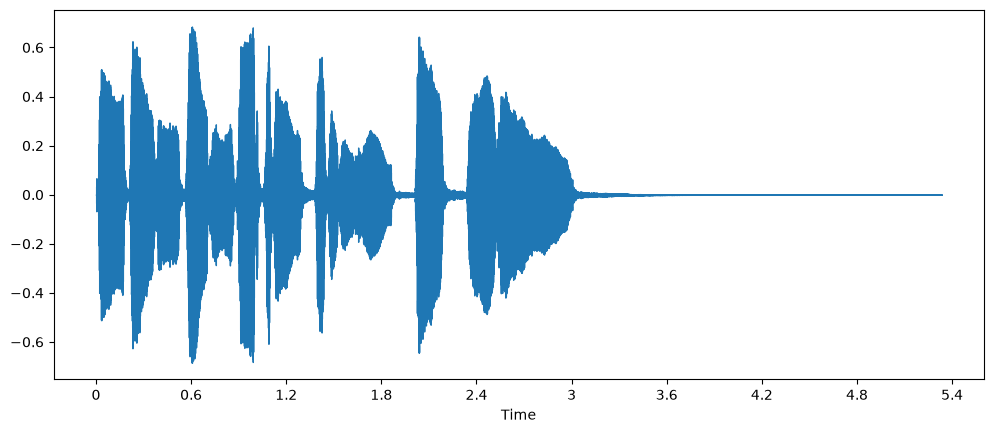

In [7]:
plt.figure().set_figwidth(12)
librosa.display.waveshow(array, sr=sampling_rate)
plt.show()

Audio(array, rate=sampling_rate)   # apasă play

🔍 **Ce să observi**
- Valorile sunt `float32`, în intervalul [-1, 1].
- `librosa.load` **resamplează implicit la 22.050 Hz**. Ca să păstrezi sampling rate-ul original, pui `sr=None`.
- Fiecare notă apare ca un „pachet” de amplitudine.

implicit: 117601 eșantioane la 22050 Hz | la 16 kHz: 85335 | original: 22050 Hz


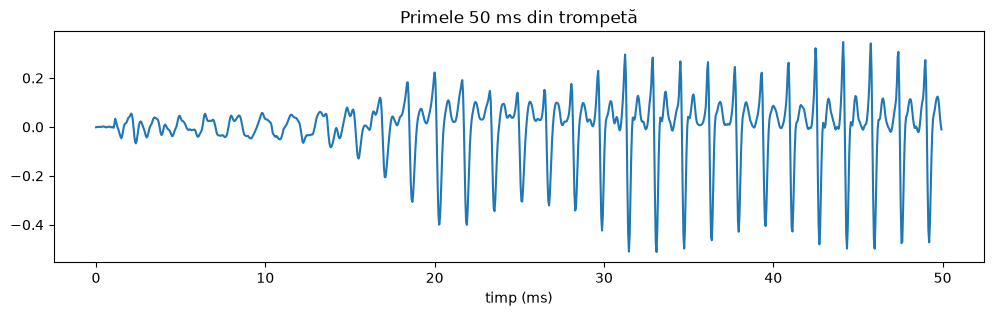

In [8]:
# 🧪 TODO 1: încarcă fișierul la 16 kHz (sampling rate-ul lui Whisper) și compară numărul de eșantioane.
# TODO: află și sampling rate-ul ORIGINAL al fișierului (sr=None).
array_16k, sr_16k = librosa.load(librosa.ex("trumpet"), sr=16000)
_, sr_orig = librosa.load(librosa.ex("trumpet"), sr=None)
print(f"implicit: {len(array)} eșantioane la {sampling_rate} Hz | la 16 kHz: {len(array_16k)} | original: {sr_orig} Hz")
# Răspuns: originalul e chiar 22.050 Hz. La 16 kHz rămân ~72,6% din eșantioane (16000 / 22050), pentru aceeași durată.

# 🧪 TODO 2: fă zoom pe primele 50 ms, ca să vezi oscilațiile individuale ale undei.
n = int(0.05 * sampling_rate)
plt.figure(figsize=(12, 3))
plt.plot(np.arange(n) / sampling_rate * 1000, array[:n])
plt.xlabel("timp (ms)"); plt.title("Primele 50 ms din trompetă")
plt.show()

## 4. Spectrul de frecvențe (domeniul frecvenței)

📖 **Teorie**
- **DFT**-ul descompune un fragment de sunet în frecvențele care îl compun și îți spune cât de puternică e fiecare. În practică îl calculezi cu algoritmul **FFT**.
- Waveform-ul și spectrul conțin **aceeași informație**, văzută diferit. Vezi tabelul de mai jos.
- Rezultatul DFT e un număr complex:
  - `np.abs()` îți dă **amplitudinea**;
  - unghiul e **faza**, pe care ML-ul o ignoră de obicei.
- **Fereastra Hanning:**
  - Ca să calculezi spectrul unui fragment, îl tai din sunet, deci îl tai **brusc** la capete.
  - FFT-ul presupune că fragmentul se repetă la nesfârșit. Acolo unde capătul nu se potrivește cu începutul apare un **„salt”**, care nu face parte din sunet.
  - FFT-ul vede saltul ca pe frecvențe în plus: energia notei se „scurge” în frecvențele din jur (**spectral leakage**), iar spectrul devine murdar.
  - Fereastra Hanning e o curbă în formă de clopot: **0 la capete, 1 la mijloc**. Înmulțești fragmentul cu ea, capetele coboară lin spre 0 și saltul dispare.
  - **Prețul:** vârful se lățește puțin, dar frecvențele false aproape dispar. Seamănă cu un fade-in/fade-out scurt în editarea audio, care elimină „click”-ul de la tăietură.
  - În practică nu o aplici de mână: `librosa.stft` și feature extractor-ul Whisper o aplică automat pe fiecare fereastră.
- **Power spectrum** = amplitudinea la pătrat.

**Waveform vs spectru, exact:**

| | **Waveform** | **Spectru** |
|---|---|---|
| Axa x | **timpul** (secunde) | **frecvența** (Hz) |
| Axa y | valoarea semnalului (amplitudinea) în acel moment | **cât de puternică** e fiecare frecvență (dB) |
| Răspunde la întrebarea | *ce valoare are semnalul la fiecare moment?* | *din ce frecvențe e făcut fragmentul?* |
| Vezi ușor | când începe și când se termină un sunet, cât de tare e | ce notă e (fundamentala), armonicile, zgomotul de fond |
| Nu vezi | ce frecvențe conține | **când** apar frecvențele: e o „fotografie” a unui fragment |

- DFT-ul trece de la waveform la spectru, iar DFT-ul invers te aduce înapoi, dacă păstrezi și faza.
- **Analogie:** la un acord de pian, waveform-ul e mișcarea complicată a membranei difuzorului în timp. Spectrul e lista clapelor apăsate și cât de tare e fiecare.
- **Spectrograma** (secțiunea 5) le combină: spectre calculate pe ferestre succesive, deci frecvențe **în timp**.

In [ ]:
# ▶️ Waveform vs spectru pe un semnal simplu: un „acord” din două note, 440 Hz (La) + 660 Hz (Mi), a doua mai încet
sr_demo = 16000
t = np.arange(0, 0.5, 1 / sr_demo)                                     # 0,5 secunde
signal = 0.6 * np.sin(2 * np.pi * 440 * t) + 0.3 * np.sin(2 * np.pi * 660 * t)

fig, ax = plt.subplots(1, 2, figsize=(14, 3))
ax[0].plot(t[:400] * 1000, signal[:400])                                # primele 25 ms
ax[0].set_xlabel("timp (ms)"); ax[0].set_ylabel("amplitudine"); ax[0].set_title("WAVEFORM: valoarea în timp")

spec = np.abs(np.fft.rfft(signal * np.hanning(len(signal))))
freqs_demo = np.fft.rfftfreq(len(signal), 1 / sr_demo)
ax[1].plot(freqs_demo, spec)
ax[1].set_xlim(0, 1500); ax[1].set_xlabel("frecvență (Hz)"); ax[1].set_ylabel("cât de puternică")
ax[1].set_title("SPECTRU: din ce frecvențe e făcut")
plt.show()
Audio(signal, rate=sr_demo)   # ascultă acordul
# În waveform vezi o undă „încâlcită”, din care nu poți citi direct ce note sunt.
# În spectru vezi clar două vârfuri, la 440 Hz și la 660 Hz. Cel de la 440 Hz e de 2 ori mai înalt (0,6 față de 0,3).

In [ ]:
# ▶️ De ce fereastra Hanning: un ton de 440 Hz, într-un fragment de 1024 de eșantioane la 16 kHz
sr_w, n = 16000, 1024
t_w = np.arange(n) / sr_w
tone = np.sin(2 * np.pi * 440 * t_w)     # 440 Hz NU încape de un număr întreg de ori în fragment (28,16 perioade)
window = np.hanning(n)
f_w = np.fft.rfftfreq(n, 1 / sr_w)

fig, ax = plt.subplots(1, 3, figsize=(16, 3))
ax[0].plot(window); ax[0].set_title("Fereastra Hanning: 0 la capete, 1 la mijloc"); ax[0].set_xlabel("eșantion")
ax[1].plot(t_w * 1000, tone, alpha=0.5, label="tăiat brusc")
ax[1].plot(t_w * 1000, tone * window, label="× Hanning")
ax[1].set_xlabel("timp (ms)"); ax[1].set_title("Fragmentul"); ax[1].legend(loc="lower left")
for sig, lab in [(tone, "fără fereastră"), (tone * window, "cu Hanning")]:
    ax[2].plot(f_w, librosa.amplitude_to_db(np.abs(np.fft.rfft(sig)), ref=np.max, top_db=None), label=lab)
ax[2].set_xlim(0, 2000); ax[2].set_ylim(-120, 5)
ax[2].set_xlabel("frecvență (Hz)"); ax[2].set_ylabel("dB"); ax[2].set_title("Spectrul aceleiași note de 440 Hz"); ax[2].legend()
plt.show()
# Fără fereastră: energia „se scurge” în multe frecvențe false din jurul lui 440 Hz (spectral leakage).
# Cu Hanning: vârful e curat, iar restul spectrului coboară mult mai jos, deci frecvențele false aproape dispar.

▶️ **Cod din curs:** spectrul primelor 4096 de eșantioane (~0,19 s, cam prima notă)

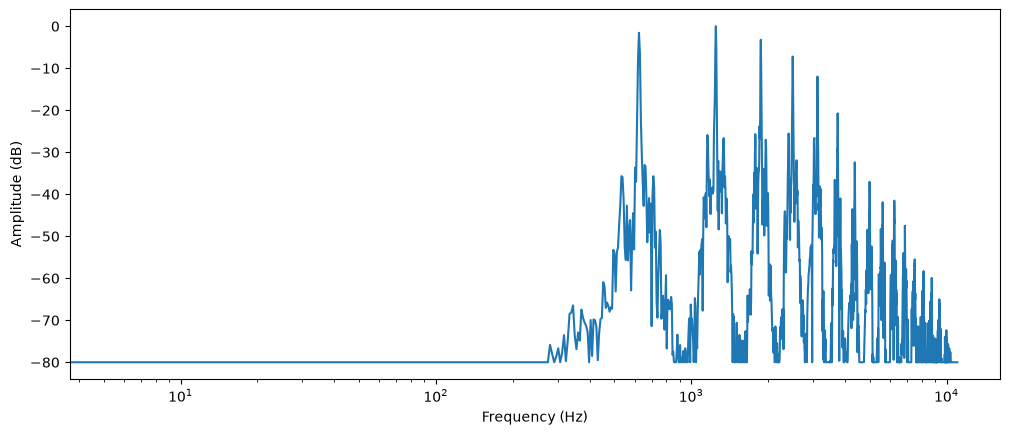

In [9]:
dft_input = array[:4096]

# calculăm DFT-ul
window = np.hanning(len(dft_input))
windowed_input = dft_input * window
dft = np.fft.rfft(windowed_input)

# spectrul de amplitudine, în decibeli
amplitude = np.abs(dft)
amplitude_db = librosa.amplitude_to_db(amplitude, ref=np.max)

# frecvența corespunzătoare fiecărui punct
frequency = librosa.fft_frequencies(sr=sampling_rate, n_fft=len(dft_input))

plt.figure().set_figwidth(12)
plt.plot(frequency, amplitude_db)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (dB)")
plt.xscale("log")
plt.show()

🔍 **Ce să observi**
- Vârfurile sunt **armonicile** notei.
- Primul vârf e la ~620 Hz, nota Mi bemol. Vârfurile următoare sunt multipli ai lui.

In [10]:
# 🧪 TODO 1: găsește frecvența celui mai puternic vârf și a primului vârf (fundamentala, sub 1000 Hz).
peak_hz = frequency[np.argmax(amplitude)]
mask = frequency < 1000
f0_hz = frequency[mask][np.argmax(amplitude[mask])]
print(f"cel mai puternic vârf: {peak_hz:.0f} Hz | fundamentala: {f0_hz:.0f} Hz | raport: {peak_hz / f0_hz:.2f}")
# Răspuns: cel mai puternic vârf e ~1250 Hz, adică 2 × ~620 Hz.
# La trompetă, armonica a 2-a e mai puternică decât fundamentala.

# 🧪 TODO 2: calculează același lucru pentru nota de la secunda 2 și compară fundamentalele.
start = 2 * sampling_rate
frag = array[start:start + 4096] * np.hanning(4096)
amp2 = np.abs(np.fft.rfft(frag))
f0_2 = frequency[mask][np.argmax(amp2[mask])]
print(f"nota de la 2 s: fundamentala ≈ {f0_2:.0f} Hz (față de {f0_hz:.0f} Hz la început)")
# Răspuns: ~926 Hz, deci altă notă, mai înaltă. Spectrul se schimbă de la o notă la alta.

cel mai puternic vârf: 1249 Hz | fundamentala: 624 Hz | raport: 2.00
nota de la 2 s: fundamentala ≈ 926 Hz (față de 624 Hz la început)


## 5. Spectrograma

📖 **Teorie**
- Spectrul e o „fotografie” la un singur moment. Ca să vezi cum se **schimbă** frecvențele în timp:
  - calculezi multe DFT-uri pe ferestre scurte;
  - le așezi una lângă alta.

  Asta e **STFT**-ul (Short-Time Fourier Transform).
- Pe grafic: axa x e timpul, axa y e frecvența, iar culoarea e intensitatea, în dB.
- Implicit, `librosa.stft` folosește:
  - ferestre de **2048** de eșantioane (`n_fft`);
  - un pas de **512** între ele (`hop_length` = `n_fft` / 4).
- Din spectrogramă poți reface waveform-ul (cu ISTFT) **doar** dacă ai și faza. Modelele care generează spectrograme scot doar amplitudinea, așa că au nevoie de un **vocoder** (sau de Griffin-Lim).

▶️ **Cod din curs**

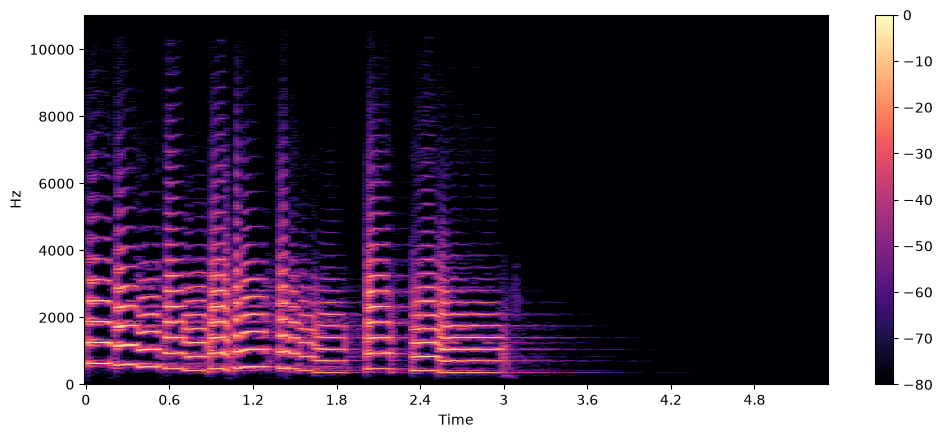

D.shape = (1025, 230) → (frecvențe = n_fft/2 + 1, cadre de timp)


In [11]:
D = librosa.stft(array)
S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_db, x_axis="time", y_axis="hz")
plt.colorbar()
plt.show()
print("D.shape =", D.shape, "→ (frecvențe = n_fft/2 + 1, cadre de timp)")

🔍 **Ce să observi**
- **Liniile orizontale** sunt armonicile fiecărei note.
- Când se schimbă nota, liniile „sar” la alte frecvențe.

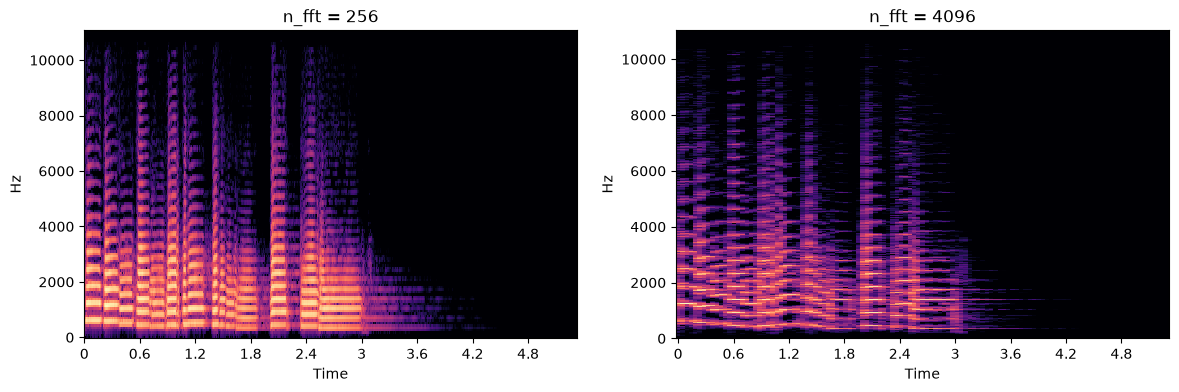

In [12]:
# 🧪 TODO: compară n_fft=256 (ferestre scurte) cu n_fft=4096 (ferestre lungi).
# Care arată mai bine CÂND începe o notă? Care arată mai precis CE frecvență are?
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, n_fft in zip(ax, [256, 4096]):
    hop = n_fft // 4
    S_n = librosa.amplitude_to_db(np.abs(librosa.stft(array, n_fft=n_fft, hop_length=hop)), ref=np.max)
    librosa.display.specshow(S_n, x_axis="time", y_axis="hz", sr=sampling_rate, hop_length=hop, ax=a)
    a.set_title(f"n_fft = {n_fft}")
plt.show()
# Răspuns: ferestrele scurte sunt precise în TIMP, iar cele lungi sunt precise în FRECVENȚĂ.
# Nu le poți avea pe amândouă deodată. 2048 e un compromis bun.

## 6. Mel spectrogram

📖 **Teorie**
- Urechea distinge mai bine diferențele între frecvențe **joase** decât între cele înalte. **Scara mel** imită asta.
- Mel spectrogram = STFT + un set de filtre (**mel filterbank**) care „înghesuie” frecvențele înalte.
- `n_mels` = numărul de benzi. Valorile uzuale sunt 40 sau 80; **Whisper turbo folosește 128**.
- Convertită în dB, se numește **log-mel spectrogram**. Asta primește Whisper la intrare.
- ⚠️ Există variante: scara „htk” vs „slaney”, putere vs amplitudine, log vs dB. Dacă un model așteaptă un mel spectrogram, trebuie calculat **exact** ca la antrenare. De aceea folosim feature extractor-ul modelului.
- Transformarea pierde informație. Ca să refaci sunetul ai nevoie de un vocoder (ex. HiFiGAN).

▶️ **Cod din curs**

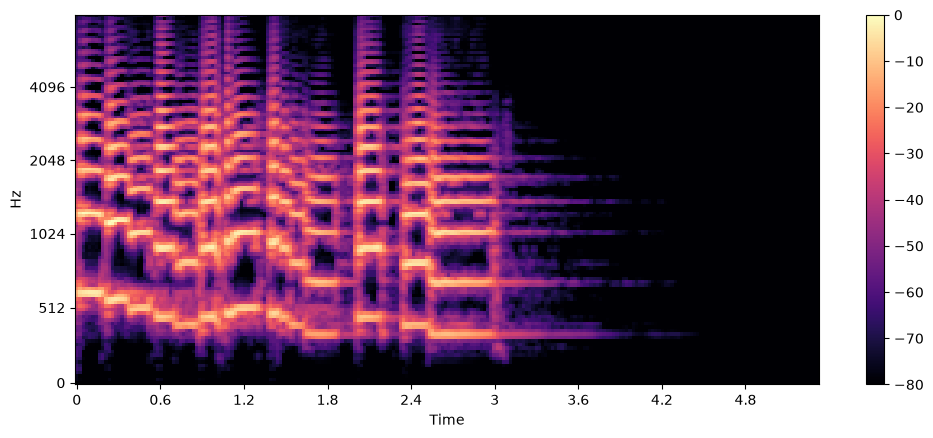

In [13]:
S = librosa.feature.melspectrogram(y=array, sr=sampling_rate, n_mels=128, fmax=8000)
S_dB = librosa.power_to_db(S, ref=np.max)

plt.figure().set_figwidth(12)
librosa.display.specshow(S_dB, x_axis="time", y_axis="mel", sr=sampling_rate, fmax=8000)
plt.colorbar()
plt.show()

🔍 **Ce să observi**
- Frecvențele joase ocupă mai mult spațiu pe verticală decât în spectrograma de la secțiunea 5.
- Armonicile înalte sunt mai înghesuite.
- Am folosit `power_to_db`, nu `amplitude_to_db`, pentru că `melspectrogram` întoarce **putere**.

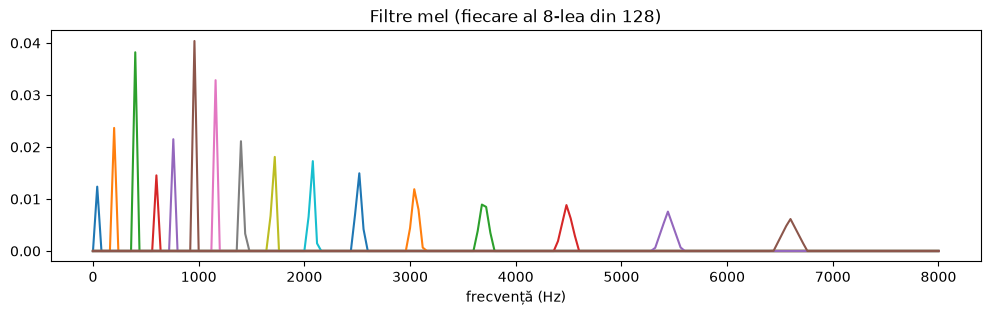

In [14]:
# 🧪 TODO: desenează filtrele mel pe care le folosește Whisper (16 kHz, n_fft=400, 128 de benzi).
# Uită-te la lățimea triunghiurilor: ce observi la frecvențele joase față de cele înalte?
mel_fb = librosa.filters.mel(sr=16000, n_fft=400, n_mels=128)    # shape (128 de benzi, 201 frecvențe)
freqs = librosa.fft_frequencies(sr=16000, n_fft=400)
plt.figure(figsize=(12, 3))
for i in range(0, 128, 8):                                        # doar fiecare al 8-lea filtru, ca să se vadă
    plt.plot(freqs, mel_fb[i])
plt.xlabel("frecvență (Hz)"); plt.title("Filtre mel (fiecare al 8-lea din 128)")
plt.show()
# Răspuns: la frecvențe joase filtrele sunt înguste (rezoluție fină), la cele înalte sunt late (rezoluție grosieră), ca urechea.

## 7. 🎯 Legătura cu proiectul: ce „vede” Whisper

📖 Feature extractor-ul Whisper face, în ordine:
1. Primește audio la **16 kHz**.
2. Îl completează cu liniște (padding) sau îl taie la exact **30 s**.
3. Calculează log-mel cu **128 de benzi**, pe ferestre de 25 ms (`n_fft=400`) mutate din 10 în 10 ms (`hop_length=160`).
   Asta dă 100 de cadre pe secundă, adică **3000 de cadre** pentru 30 s.
4. Encoderul reduce apoi cadrele la jumătate: **1500 de vectori**, câte unul la 20 ms. Pe aceștia îi vom da LLM-ului.

sampling_rate=16000 | n_mels=128 | n_fft=400 | hop_length=160 | chunk=30s
input_features: (1, 128, 3000)


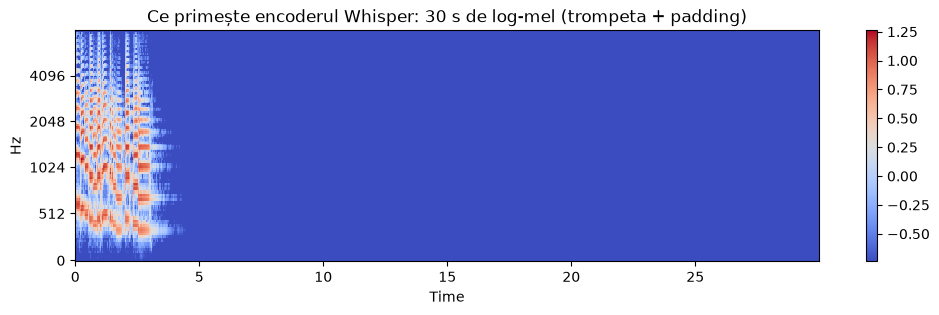

In [15]:
from transformers import WhisperFeatureExtractor

fe = WhisperFeatureExtractor.from_pretrained("openai/whisper-large-v3-turbo")   # descarcă doar config-ul (câțiva KB)
print(f"sampling_rate={fe.sampling_rate} | n_mels={fe.feature_size} | n_fft={fe.n_fft} | hop_length={fe.hop_length} | chunk={fe.chunk_length}s")

features = fe(array_16k, sampling_rate=16000, return_tensors="np").input_features
print("input_features:", features.shape)    # (batch, n_mels, cadre)

plt.figure(figsize=(12, 3))
librosa.display.specshow(features[0], x_axis="time", y_axis="mel", sr=16000, hop_length=160)
plt.colorbar(); plt.title("Ce primește encoderul Whisper: 30 s de log-mel (trompeta + padding)")
plt.show()

🔍 **Ce să observi**
- Trompeta ocupă doar primele ~5 s. Restul de ~25 s e **padding**, adică liniște.
- Encoderul primește mereu 3000 de cadre, indiferent cât de scurt e sunetul.

De aici vine întrebarea din proiect: câți tokeni audio dăm LLM-ului, pe toți 1500 sau doar cei care corespund duratei reale? E Q3 din [specs/PROJECT.md](../../../specs/PROJECT.md#întrebări-deschise).

## 📌 Ce trebuie să reții
- Audio digital = eșantioane la un **sampling rate** fix. Pentru vorbire și pentru Whisper: **16 kHz**.
- **Nyquist:** poți captura frecvențe până la sampling rate / 2. Sub limită apare aliasing.
- Modelele lucrează cu **float32 în [-1, 1]**. În audio digital, 0 dB e maximul.
- **Waveform** = timp. **Spectru** = frecvențe la un moment dat. **Spectrogramă** = frecvențe în timp (STFT).
- Ferestrele STFT impun un **compromis**: precizie în timp sau precizie în frecvență.
- **Log-mel spectrogram** = spectrogramă pe scara urechii, în dB. Asta e intrarea lui Whisper: 128 × 3000 pentru 30 s.
- Mel spectrogram-ul se calculează **exact ca la antrenarea modelului**, cu feature extractor-ul lui.

## ❓ Verifică-te
<details><summary><b>1. De ce e suficient 16 kHz pentru vorbire?</b></summary>

Vorbirea are frecvențe sub ~8 kHz, iar Nyquist spune că la 16 kHz poți captura până la 8 kHz. Un sampling rate mai mare doar crește costul de calcul.

</details>

<details><summary><b>2. Câte valori are un clip de 7,8 s la 16 kHz?</b></summary>

7,8 × 16.000 = **124.800** de eșantioane.

</details>

<details><summary><b>3. De ce folosim fereastra Hanning înainte de FFT?</b></summary>

Capetele tăiate brusc ale fragmentului introduc frecvențe false (spectral leakage). Fereastra le atenuează treptat.

</details>

<details><summary><b>4. Ce diferă între spectrogramă și mel spectrogram?</b></summary>

Axa frecvenței: liniară în Hz la spectrogramă, pe scara mel (perceptuală) la mel spectrogram, unde frecvențele înalte sunt comprimate de filtre.

</details>

<details><summary><b>5. Ce shape are intrarea lui Whisper turbo pentru 5 s de audio, și de ce?</b></summary>

**(1, 128, 3000)**. Orice audio e completat sau tăiat la 30 s: 128 de benzi mel × 3000 de cadre de 10 ms.

</details>

## ➡️ Următorul: [02_load_and_explore.ipynb](02_load_and_explore.ipynb)